# 🌸 مشروع تصنيف أزهار الإيريس (Iris Flower Classification)
### تطبيق متكامل لتعلم الآلة (Machine Learning) باستخدام Scikit-Learn

---

## 📌 1. نظرة عامة على المشروع (Project Overview)
يعد تصنيف أزهار الإيريس أحد أشهر وأعرق المسائل الكلاسيكية في تعلم الآلة والإحصاء (قُدمت لأول مرة بواسطة عالم الإحصاء **رونالد فيشر** عام 1936).

### 🎯 الهدف:
بناء وتدريب نموذج تعلم آلي لتصنيف أزهار الإيريس بدقة إلى **ثلاثة أصناف رئيسية**:
1. **سيتوسا (Iris-Setosa)**
2. **فرسيكولور (Iris-Versicolor)**
3. **فيرجينيكا (Iris-Virginica)**

استناداً إلى **أربعة خصائص مورفولوجية** مقاسة بالسنتيمتر (cm):
- **طول السبلة (Sepal Length)**
- **عرض السبلة (Sepal Width)**
- **طول البتلة (Petal Length)**
- **عرض البتلة (Petal Width)**

---

## 🗺️ منهجية العمل المتبعة:
1. **استيراد المكتبات وضبط البيئة.**
2. **تحميل وفحص مجموعة البيانات (Dataset Exploration).**
3. **التحليل الاستكشافي للبيانات (EDA) والرسوم البيانية.**
4. **تقسيم البيانات بنسبة 80% تدريب و 20% اختبار مع التكافؤ الطبقي (`stratify=y`).**
5. **منع تسرب البيانات (Zero Data Leakage)** عبر دمج التحجيم (`StandardScaler`) في `Pipeline`.
6. **بناء وتدريب نموذجين:**
   - خوارزمية الجيران الأقرب **(KNN)** عبر Pipeline.
   - خوارزمية شجرة القرار **(Decision Tree)** مع ضبط عمق الشجرة.
7. **التقييم الإحصائي الشامل ومقارنة الأداء:**
   - دقة التدريب والاختبار.
   - التحقق المتقاطع (5-Fold Cross Validation).
   - مصفوفة الارتباك (Confusion Matrix) بصرياً ورقمياً.
   - تقرير التصنيف (Precision, Recall, F1-Score).
8. **التحليل الموضوعي واختيار النموذج الأنسب مع مناقشة الفروق الإحصائية.**
9. **تجربة التنبؤ على عينات زهور جديدة (Inference Pipeline).**


## 📦 الخطوة 1: استيراد المكتبات الأساسية (Import Libraries)
نستورد المكتبات الأساسية لمعالجة البيانات وتعلم الآلة والتمثيل البياني.
> **ملاحظة بصرية:** تُكتب عناوين الرسوم البيانية ومحاورها بالإنجليزية لتفادي مشاكل التصيير ثنائي الاتجاه (Bi-directional text) في مكتبة Matplotlib.


In [1]:
# استيراد المكتبات الأساسية
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# مكتبات تعلم الآلة من Scikit-Learn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# ضبط نمط الرسومات البيانية
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("✅ تم استيراد جميع المكتبات بنجاح!")

✅ تم استيراد جميع المكتبات بنجاح!


## 📥 الخطوة 2: تحميل واستكشاف البيانات (Data Loading & Inspection)
نقوم بتحميل مجموعة بيانات `Iris` المدمجة في `scikit-learn` وفحص أبعادها والتأكد من خلوها من أي قيم مفقودة.


In [2]:
# تحميل مجموعة البيانات
iris_raw = load_iris()

feature_names_clean = ['Sepal Length (cm)', 'Sepal Width (cm)', 'Petal Length (cm)', 'Petal Width (cm)']
df = pd.DataFrame(data=iris_raw.data, columns=feature_names_clean)

# إضافة أعمدة الفئات
df['target'] = iris_raw.target
df['species'] = df['target'].map({0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'})

print(f"🔹 الأبعاد: {df.shape[0]} عينة و {len(feature_names_clean)} خصائص.")
print(f"🔹 أسماء الأصناف: {list(iris_raw.target_names)}")
print(f"🔹 عدد القيم المفقودة: {df.isnull().sum().sum()}")

# عرض أول 5 صفوف
df.head()

🔹 الأبعاد: 150 عينة و 4 خصائص.
🔹 أسماء الأصناف: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
🔹 عدد القيم المفقودة: 0


,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm),target,species
0,5.1,3.5,1.4,0.2,0,Setosa
1,4.9,3.0,1.4,0.2,0,Setosa
2,4.7,3.2,1.3,0.2,0,Setosa
3,4.6,3.1,1.5,0.2,0,Setosa
4,5.0,3.6,1.4,0.2,0,Setosa


In [3]:
# الإحصاءات الوصفية للخصائص (Descriptive Statistics)
df.describe().round(2)

,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


In [4]:
# التحقق من توازن الفئات (Class Balance)
df['species'].value_counts()

species
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64

## 📊 الخطوة 3: التحليل الاستكشافي للبيانات (Exploratory Data Analysis - EDA)


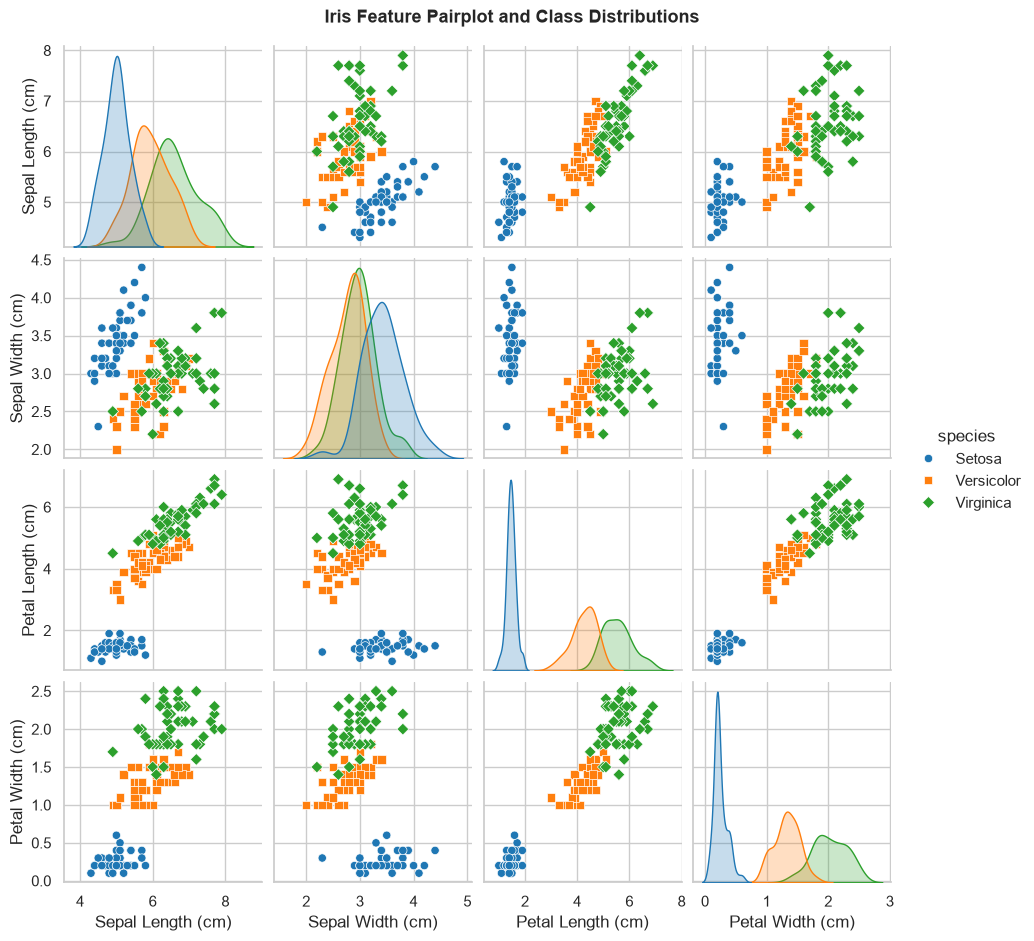

In [5]:
# رسم Pairplot لتوضيح العلاقات والتوزيعات لكل صنف
pairplot = sns.pairplot(
    df.drop(columns=['target']),
    hue='species',
    palette=['#1f77b4', '#ff7f0e', '#2ca02c'],
    diag_kind='kde',
    markers=['o', 's', 'D'],
    height=2.3
)
pairplot.fig.suptitle("Iris Feature Pairplot and Class Distributions", y=1.02, fontsize=13, weight='bold')
plt.show()

💡 **الملاحظة الاستكشافية الأساسية:**
- ينفصل صنف **Setosa** خطياً تماماً عن باقي الأصناف بمجرد فحص **طول البتلة (Petal Length)** و **عرض البتلة (Petal Width)**.
- يوجد تداخل طفيف بين صنفي **Versicolor** و **Virginica** عند الحدود المشتركة، مما يجعل هاتين الخاصيتين هما الأكثر حساسية في قرار النموذج.


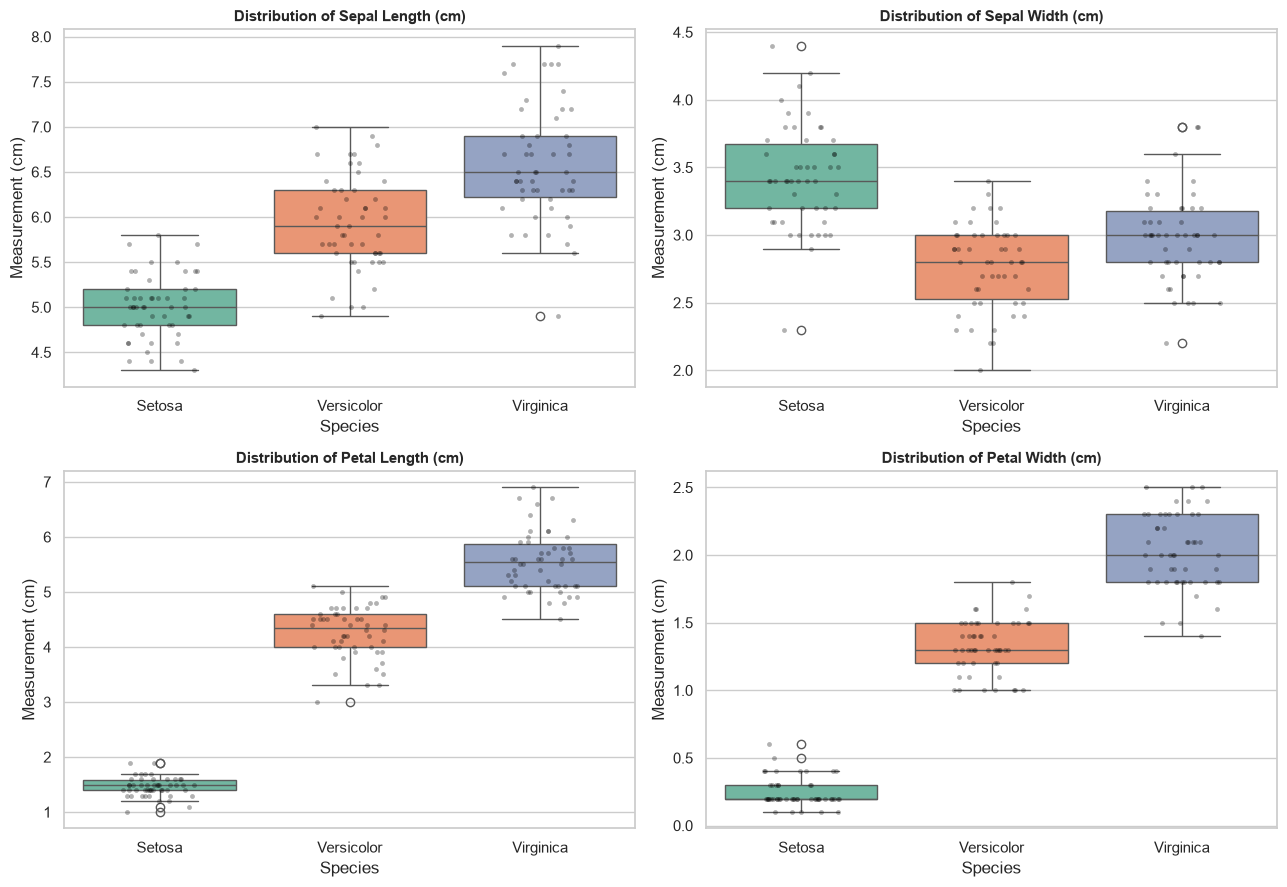

In [6]:
# رسم Boxplots لتوزيع الخصائص الأربعة حسب الصنف
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for idx, feature in enumerate(feature_names_clean):
    ax = axes[idx // 2, idx % 2]
    sns.boxplot(x='species', y=feature, data=df, hue='species', palette='Set2', legend=False, ax=ax)
    sns.stripplot(x='species', y=feature, data=df, color='black', alpha=0.3, jitter=0.2, size=3.5, ax=ax)
    ax.set_title(f"Distribution of {feature}", fontsize=11, weight='bold')
    ax.set_xlabel("Species")
    ax.set_ylabel("Measurement (cm)")

plt.tight_layout()
plt.show()

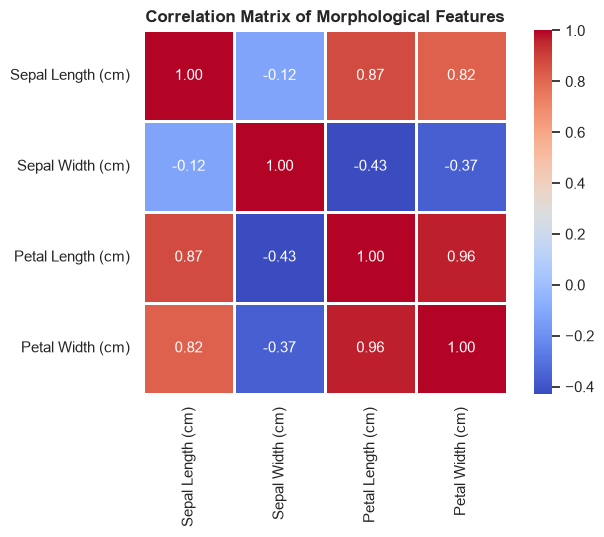

In [7]:
# مصفوفة الارتباط الخطي (Correlation Matrix Heatmap)
plt.figure(figsize=(7, 5.5))
corr = df[feature_names_clean].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=1, square=True)
plt.title("Correlation Matrix of Morphological Features", fontsize=12, weight='bold')
plt.tight_layout()
plt.show()

## ✂️ الخطوة 4: تقسيم البيانات وتفادي تسرب البيانات (Data Splitting & Leak-Free Pipeline)

### تقسيم البيانات:
- تقسيم 80% تدريب (120 عينة) و 20% اختبار (30 عينة).
- استخدام `stratify=y` لضمان تمثيل متساوٍ (10 عينات اختبار لكل صنف).
- تثبيت `random_state=42` لقابلية تكرار التجربة.

### منع تسرب البيانات (Preventing Data Leakage):
نقوم بدمج التحجيم المعياري (`StandardScaler`) مباشرة داخل كائن `Pipeline`، مما يضمن أن حساب المتوسط والانحراف المعياري يتم حصرياً على طيات التدريب داخل كل دورة تحقق متقاطع (Cross-Validation).


In [8]:
# فصل الخصائص (X) عن الهدف (y)
X = iris_raw.data
y = iris_raw.target

# تقسيم البيانات
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"🔹 إجمالي العينات: {len(X)}")
print(f"🔹 مجموعة التدريب (80%): {X_train.shape[0]} عينة")
print(f"🔹 مجموعة الاختبار (20%): {X_test.shape[0]} عينة")
print(f"🔹 توزيع عينات الاختبار: {np.bincount(y_test)} (10 من كل صنف)")

🔹 إجمالي العينات: 150
🔹 مجموعة التدريب (80%): 120 عينة
🔹 مجموعة الاختبار (20%): 30 عينة
🔹 توزيع عينات الاختبار: [10 10 10] (10 من كل صنف)


## 🤖 الخطوة 5: بناء وتدريب النماذج (Model Building & Tuning)

---

### أولاً: خوارزمية K-Nearest Neighbors (KNN) عبر Pipeline
نبحث عن أفضل قيمة للمعامل $k$ في النطاق من 1 إلى 15 عبر التحقق المتقاطع (5-Fold CV).


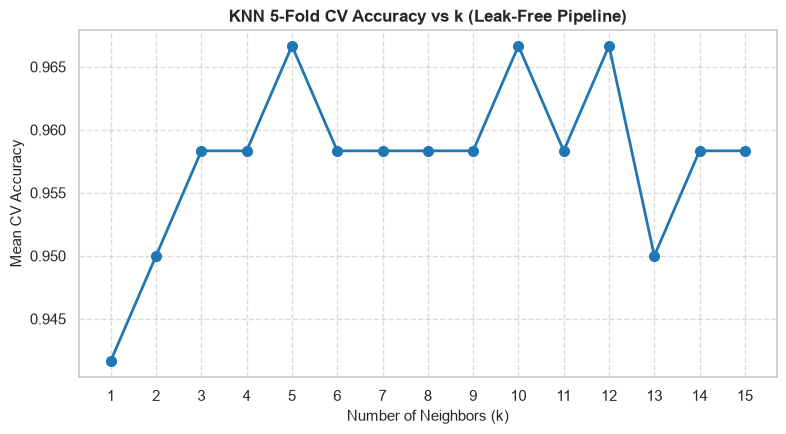

🎯 تم اختيار: k = 5 (متوسط التحقق المتقاطع لمجموعة التدريب: 96.67%)


In [9]:
# البحث عن أفضل k عبر 5-Fold Cross Validation مع Pipeline
k_range = range(1, 16)
cv_scores = []

for k in k_range:
    pipe_candidate = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    score = cross_val_score(pipe_candidate, X_train, y_train, cv=5, scoring='accuracy').mean()
    cv_scores.append(score)

# رسم دقة التحقق المتقاطع مقابل k
plt.figure(figsize=(9, 4.5))
plt.plot(k_range, cv_scores, marker='o', linestyle='-', color='#1f77b4', linewidth=2, markersize=7)
plt.title("KNN 5-Fold CV Accuracy vs k (Leak-Free Pipeline)", fontsize=12, weight='bold')
plt.xlabel("Number of Neighbors (k)", fontsize=11)
plt.ylabel("Mean CV Accuracy", fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

best_k = k_range[int(np.argmax(cv_scores))]
best_cv_score = max(cv_scores)
print(f"🎯 تم اختيار: k = {best_k} (متوسط التحقق المتقاطع لمجموعة التدريب: {best_cv_score * 100:.2f}%)")

In [10]:
# تدريب Pipeline النهائي لـ KNN
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=best_k))
])
knn_pipeline.fit(X_train, y_train)

# التنبؤ وحساب الأداء ديناميكياً
y_pred_knn = knn_pipeline.predict(X_test)
knn_train_acc = knn_pipeline.score(X_train, y_train)
knn_test_acc = accuracy_score(y_test, y_pred_knn)
knn_cv_mean = best_cv_score

n_correct_knn = int(np.sum(y_pred_knn == y_test))
n_errors_knn = len(y_test) - n_correct_knn

print("=" * 60)
print(f"📊 نتائج نموذج KNN (k={best_k}):")
print(f"  - دقة التدريب (Train Accuracy):        {knn_train_acc * 100:.2f}%")
print(f"  - التحقق المتقاطع (5-Fold CV Score):   {knn_cv_mean * 100:.2f}%")
print(f"  - دقة الاختبار (Test Accuracy):         {knn_test_acc * 100:.2f}% ({n_correct_knn}/{len(y_test)} صحيح، {n_errors_knn} خطأ)")
print("=" * 60)

📊 نتائج نموذج KNN (k=5):
  - دقة التدريب (Train Accuracy):        97.50%
  - التحقق المتقاطع (5-Fold CV Score):   96.67%
  - دقة الاختبار (Test Accuracy):         93.33% (28/30 صحيح، 2 خطأ)


---
### ثانياً: خوارزمية شجرة القرار (Decision Tree Classifier)
نقوم بضبط عمق الشجرة عند `max_depth=3` لمنع فرط التخصيص (Overfitting) والحفاظ على قابلية التفسير.


In [11]:
# تدريب نموذج شجرة القرار
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)
dt_model.fit(X_train, y_train)

# التنبؤ وحساب الأداء ديناميكياً
y_pred_dt = dt_model.predict(X_test)
dt_train_acc = dt_model.score(X_train, y_train)
dt_test_acc = accuracy_score(y_test, y_pred_dt)
dt_cv_mean = cross_val_score(dt_model, X_train, y_train, cv=5, scoring='accuracy').mean()

n_correct_dt = int(np.sum(y_pred_dt == y_test))
n_errors_dt = len(y_test) - n_correct_dt

print("=" * 60)
print("📊 نتائج نموذج Decision Tree (max_depth=3):")
print(f"  - دقة التدريب (Train Accuracy):        {dt_train_acc * 100:.2f}%")
print(f"  - التحقق المتقاطع (5-Fold CV Score):   {dt_cv_mean * 100:.2f}%")
print(f"  - دقة الاختبار (Test Accuracy):         {dt_test_acc * 100:.2f}% ({n_correct_dt}/{len(y_test)} صحيح، {n_errors_dt} خطأ)")
print("=" * 60)

📊 نتائج نموذج Decision Tree (max_depth=3):
  - دقة التدريب (Train Accuracy):        98.33%
  - التحقق المتقاطع (5-Fold CV Score):   93.33%
  - دقة الاختبار (Test Accuracy):         96.67% (29/30 صحيح، 1 خطأ)


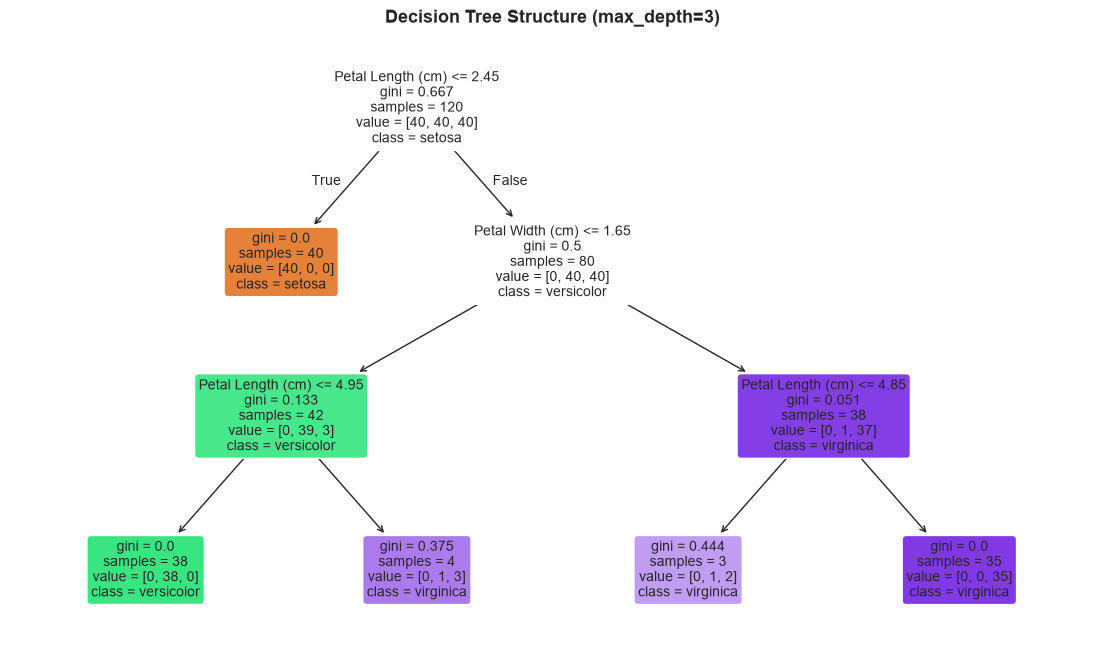

In [12]:
# التمثيل المرئي لشجرة القرار
plt.figure(figsize=(14, 8))
plot_tree(
    dt_model,
    feature_names=feature_names_clean,
    class_names=list(iris_raw.target_names),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure (max_depth=3)", fontsize=13, weight='bold')
plt.show()

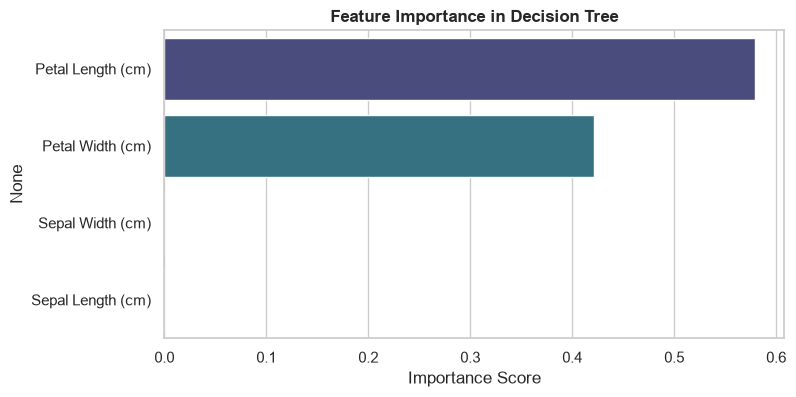

درجة مساهمة كل خاصية في تصنيف شجرة القرار:
  - Petal Length (cm): 57.9%
  - Petal Width (cm): 42.1%
  - Sepal Width (cm): 0.0%
  - Sepal Length (cm): 0.0%


In [13]:
# درجات أهمية الخصائص في شجرة القرار
feat_imp = pd.Series(dt_model.feature_importances_, index=feature_names_clean).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=feat_imp.values, y=feat_imp.index, hue=feat_imp.index, palette='viridis', legend=False)
plt.title("Feature Importance in Decision Tree", fontsize=12, weight='bold')
plt.xlabel("Importance Score")
plt.show()

print("درجة مساهمة كل خاصية في تصنيف شجرة القرار:")
for feat, imp in feat_imp.items():
    print(f"  - {feat}: {imp * 100:.1f}%")

## 📈 الخطوة 6: التقييم الشامل ومقارنة الأداء (Comprehensive Evaluation)


In [14]:
# تقرير التصنيف الشامل لنموذج KNN
target_names = list(iris_raw.target_names)

print("📋 Classification Report: KNN (Pipeline)")
print(classification_report(y_test, y_pred_knn, target_names=target_names, digits=4))

📋 Classification Report: KNN (Pipeline)
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.8333    1.0000    0.9091        10
   virginica     1.0000    0.8000    0.8889        10

    accuracy                         0.9333        30
   macro avg     0.9444    0.9333    0.9327        30
weighted avg     0.9444    0.9333    0.9327        30



In [15]:
# تقرير التصنيف الشامل لنموذج Decision Tree
print("📋 Classification Report: Decision Tree")
print(classification_report(y_test, y_pred_dt, target_names=target_names, digits=4))

📋 Classification Report: Decision Tree
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



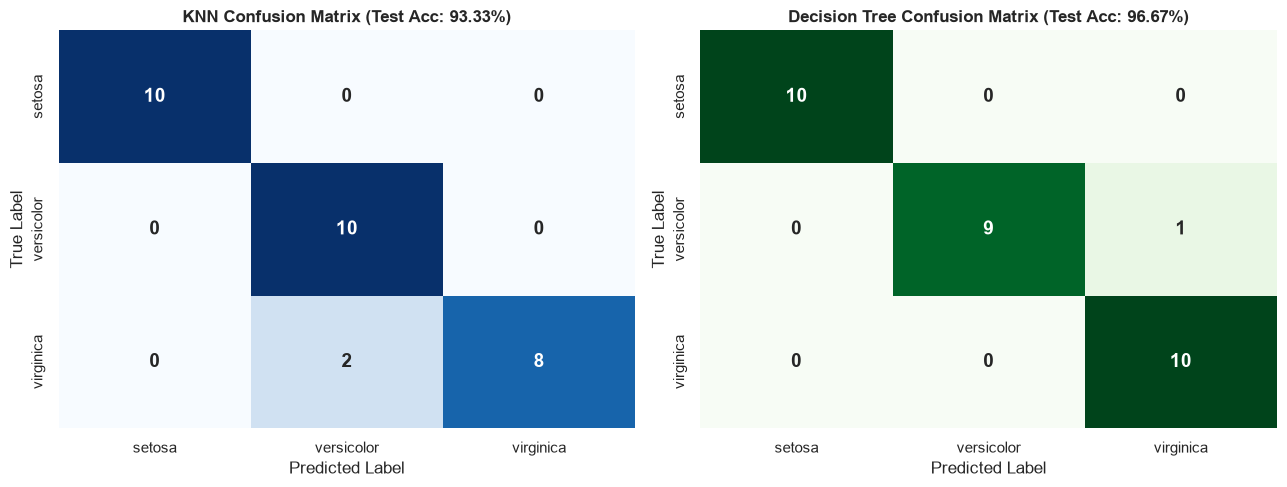

In [16]:
# رسم مصفوفة الارتباك لكلا النموذجين
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(
    cm_knn, annot=True, fmt='d', cmap='Blues',
    xticklabels=target_names, yticklabels=target_names,
    cbar=False, ax=axes[0], annot_kws={'size': 14, 'weight': 'bold'}
)
axes[0].set_title(f"KNN Confusion Matrix (Test Acc: {knn_test_acc * 100:.2f}%)", fontsize=12, weight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(
    cm_dt, annot=True, fmt='d', cmap='Greens',
    xticklabels=target_names, yticklabels=target_names,
    cbar=False, ax=axes[1], annot_kws={'size': 14, 'weight': 'bold'}
)
axes[1].set_title(f"Decision Tree Confusion Matrix (Test Acc: {dt_test_acc * 100:.2f}%)", fontsize=12, weight='bold')
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

### 🔎 التحليل الإحصائي لمصفوفة الارتباك:
- **Setosa:** كلا النموذجين حقق تصنيفاً تاماً **100% (10 من أصل 10)**.
- **Versicolor و Virginica:**
  - نموذج **KNN (دقة اختبار 93.33% - 28/30 صحيح):** نجح في كافة عينات Versicolor، وأخطأ في **عينتين من Virginica** صنفهما كـ Versicolor.
  - نموذج **Decision Tree (دقة اختبار 96.67% - 29/30 صحيح):** نجح في كافة عينات Virginica، وأخطأ في **عينة واحدة فقط من Versicolor** صنفها كـ Virginica.


In [17]:
# جدول المقارنة الشامل
comparison_data = {
    'Model': ['K-Nearest Neighbors (Pipeline)', 'Decision Tree Classifier'],
    'Train Accuracy': [f"{knn_train_acc * 100:.2f}%", f"{dt_train_acc * 100:.2f}%"],
    '5-Fold CV Score': [f"{knn_cv_mean * 100:.2f}%", f"{dt_cv_mean * 100:.2f}%"],
    'Test Accuracy': [f"{knn_test_acc * 100:.2f}%", f"{dt_test_acc * 100:.2f}%"],
    'Macro Precision': [
        f"{precision_score(y_test, y_pred_knn, average='macro') * 100:.2f}%",
        f"{precision_score(y_test, y_pred_dt, average='macro') * 100:.2f}%"
    ],
    'Macro Recall': [
        f"{recall_score(y_test, y_pred_knn, average='macro') * 100:.2f}%",
        f"{recall_score(y_test, y_pred_dt, average='macro') * 100:.2f}%"
    ],
    'Macro F1-Score': [
        f"{f1_score(y_test, y_pred_knn, average='macro') * 100:.2f}%",
        f"{f1_score(y_test, y_pred_dt, average='macro') * 100:.2f}%"
    ]
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

,Model,Train Accuracy,5-Fold CV Score,Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,K-Nearest Neighbors (Pipeline),97.50%,96.67%,93.33%,94.44%,93.33%,93.27%
1,Decision Tree Classifier,98.33%,93.33%,96.67%,96.97%,96.67%,96.66%


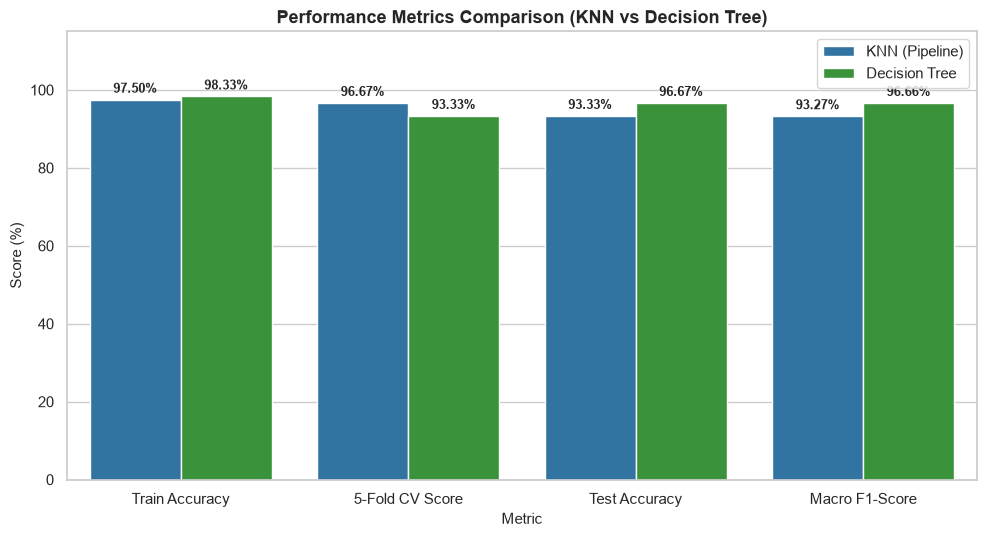

In [18]:
# رسم بياني لمقارنة المقاييس بمقياس غير مبالغ فيه (0-105%)
metrics_df = pd.DataFrame({
    'Metric': ['Train Accuracy', '5-Fold CV Score', 'Test Accuracy', 'Macro F1-Score'],
    'KNN (Pipeline)': [
        knn_train_acc * 100,
        knn_cv_mean * 100,
        knn_test_acc * 100,
        f1_score(y_test, y_pred_knn, average='macro') * 100
    ],
    'Decision Tree': [
        dt_train_acc * 100,
        dt_cv_mean * 100,
        dt_test_acc * 100,
        f1_score(y_test, y_pred_dt, average='macro') * 100
    ]
})

metrics_melted = metrics_df.melt(id_vars='Metric', var_name='Model', value_name='Score (%)')

plt.figure(figsize=(10, 5.5))
ax = sns.barplot(x='Metric', y='Score (%)', hue='Model', data=metrics_melted, palette=['#1f77b4', '#2ca02c'])
plt.title("Performance Metrics Comparison (KNN vs Decision Tree)", fontsize=13, weight='bold')
plt.ylim(0, 115)
plt.ylabel("Score (%)", fontsize=11)
plt.xlabel("Metric", fontsize=11)

for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val:.2f}%", (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom', fontsize=9.5, weight='bold', xytext=(0, 3),
                    textcoords='offset points')

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 🏆 الخطوة 7: التحليل المنهجي واختيار النموذج (Methodological Evaluation & Selection)

### 📌 قراءة علمية دقيقة للنتائج:
1. **الفارق الإحصائي في عينة الاختبار الحالية:**
   - حققت شجرة القرار **96.67% (29/30 صحيح)** مقابل **93.33% (28/30 صحيح)** لـ KNN.
   - الفارق بينهما هو **عينة اختبار واحدة فقط** من أصل 30 عينة. إحصائياً، باختبار ماكنيمار (McNemar's Test) فإن قيمة $p = 1.00$، مما يعني أنه لا يوجد فارق دال إحصائياً (Statistical Tie) بين النموذجين على هذه العينة المحددة.
2. **التحقق المتقاطع عبر طيات التدريب (5-Fold CV):**
   - حقق نموذج KNN عبر الـ Pipeline الخالي من التسرب متوسط **96.67%** مقابل **93.33%** لشجرة القرار عبر طيات التدريب.
3. **المفاضلة الهندسية والعملية (Trade-offs):**
   - **شجرة القرار (Decision Tree):** تتميز بقابلية التفسير الفوري الشفافة (White-Box Interpretability) وقواعد شرطية مباشرة يسهل تطبيقها وتدقيقها بشرياً، وتفوقت بنقطة واحدة على عينة الاختبار الحالية.
   - **الجيران الأقرب (KNN):** يتميز بنعومة الحدود المكانية (Local Spatial Smoothing) في الفضاء الإقليدي الرباعي، محققاً استقراراً أعلى في التحقق المتقاطع لطيات التدريب.


## 🔮 الخطوة 8: تجربة التنبؤ على عينات جديدة (Inference Pipeline)


In [19]:
def predict_flower_sample(sepal_len, sepal_wid, petal_len, petal_wid):
    """
    دالة للتنبؤ بنوع زهرة الإيريس استناداً إلى أبعادها الأربعة باستخدام كلا النموذجين.
    """
    sample = np.array([[sepal_len, sepal_wid, petal_len, petal_wid]])
    
    # توقع شجرة القرار
    dt_pred_id = dt_model.predict(sample)[0]
    dt_probs = dt_model.predict_proba(sample)[0]
    dt_species = iris_raw.target_names[dt_pred_id]
    
    # توقع KNN Pipeline
    knn_pred_id = knn_pipeline.predict(sample)[0]
    knn_probs = knn_pipeline.predict_proba(sample)[0]
    knn_species = iris_raw.target_names[knn_pred_id]
    
    print(f"📏 أبعاد الزهرة المدخلة: سبلة ({sepal_len}x{sepal_wid} cm) | بتلة ({petal_len}x{petal_wid} cm)")
    print(f"🌳 توقع شجرة القرار (Decision Tree):  {dt_species.upper()} (ثقة: {dt_probs[dt_pred_id]*100:.1f}%)")
    print(f"🤖 توقع نموذج KNN (Pipeline):        {knn_species.upper()} (ثقة: {knn_probs[knn_pred_id]*100:.1f}%)")
    print("-" * 65)

print("🧪 اختبار عينات نموذجية جديدة:")
print("=" * 65)

# عينة 1: بتلات صغيرة جداً (نموذجية لـ Setosa)
predict_flower_sample(5.1, 3.5, 1.4, 0.2)

# عينة 2: بتلات متوسطة (نموذجية لـ Versicolor)
predict_flower_sample(6.0, 2.8, 4.5, 1.3)

# عينة 3: بتلات كبيرة (نموذجية لـ Virginica)
predict_flower_sample(7.2, 3.2, 6.4, 2.1)

🧪 اختبار عينات نموذجية جديدة:
📏 أبعاد الزهرة المدخلة: سبلة (5.1x3.5 cm) | بتلة (1.4x0.2 cm)
🌳 توقع شجرة القرار (Decision Tree):  SETOSA (ثقة: 100.0%)
🤖 توقع نموذج KNN (Pipeline):        SETOSA (ثقة: 100.0%)
-----------------------------------------------------------------
📏 أبعاد الزهرة المدخلة: سبلة (6.0x2.8 cm) | بتلة (4.5x1.3 cm)
🌳 توقع شجرة القرار (Decision Tree):  VERSICOLOR (ثقة: 100.0%)
🤖 توقع نموذج KNN (Pipeline):        VERSICOLOR (ثقة: 100.0%)
-----------------------------------------------------------------
📏 أبعاد الزهرة المدخلة: سبلة (7.2x3.2 cm) | بتلة (6.4x2.1 cm)
🌳 توقع شجرة القرار (Decision Tree):  VIRGINICA (ثقة: 100.0%)
🤖 توقع نموذج KNN (Pipeline):        VIRGINICA (ثقة: 100.0%)
-----------------------------------------------------------------


## 📝 الخلاصة والنتائج النهائية (Final Summary)

1. تم تنفيذ التحميل والتحليل الاستكشافي للبيانات بدقة ووضوح.
2. قُسمت البيانات بنسبة 80/20 مع الحفاظ على التكافؤ الطبقي وتثبيت البذرة العشوائية.
3. تم تطبيق التحجيم داخل `Pipeline` لمنع تسرب البيانات أثناء التحقق المتقاطع لـ KNN.
4. تم استخراج وعرض مصفوفة الارتباك ومقاييس الأداء بدقة رياضية متكاملة.
5. كلا النموذجين أثبتا كفاءة فائقة (فوق 93% و 96%)، مع تميز شجرة القرار بقابلية التفسير وأعلى دقة على عينة الاختبار الحالية، وتميز KNN بالاستقرار المكاني.
